# AI Semiconductor Supply Chain: Packaging Backlog Prediction & Capacity Intelligence

## Business Problem

The rapid expansion of AI infrastructure has increased the importance of semiconductor manufacturing capacity and advanced packaging operations. Packaging queues create production bottlenecks, delay downstream deliveries, and complicate capacity planning.

This project analyzes a modeled global semiconductor supply chain dataset from kaggle to identify factors associated with packaging backlogs and develop a machine learning model for predicting backlog duration.

## Project Objectives

1. Analyze packaging bottlenecks across facilities, regions, and packaging technologies.
2. Investigate relationships between manufacturing capacity, utilization, process technology, and packaging backlog.
3. Develop and compare regression models to predict packaging backlog (measured in weeks).
4. Evaluate model performance using RMSE, MAE, and R².
5. Identify facilities requiring operational attention through a transparent priority-scoring methodology.
6. Export model outputs to Tableau for an interactive predictive operations dashboard for stakeholders.

## Business Question

**Which semiconductor facilities are associated with the greatest packaging delay exposure, how accurately can we predict backlog duration, and where should operations managers prioritize their attention?**

## Tools

- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- LightGBM
- CatBoost
- Tableau

**Data limitation:** The dataset represents modeled cross-sectional facility observations rather than a historical time series. This analysis predicts backlog duration, not future weekly backlog trends.

In [7]:
%pip install pandas numpy matplotlib seaborn scikit-learn lightgbm catboost joblib

Note: you may need to restart the kernel to use updated packages.


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import BayesianRidge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

import joblib

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import BayesianRidge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

import joblib

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

print("Libraries imported successfully!")

Libraries imported successfully!


In [11]:
#load and display data file

file_path = "global_ai_semiconductor_supply_chain.csv"

df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)

display(df.head())

Dataset shape: (10000, 29)


,facility_id,company_name,country_location,facility_type,process_node_nm,wafer_size_mm,monthly_capacity_wafers,capacity_utilization_pct,die_yield_pct,defect_density_per_cm2,lithography_technology,lithography_tool_supplier,lithography_lead_time_months,advanced_packaging_type,hbm_integration_spec,packaging_backlog_weeks,power_consumption_mw,water_recycling_rate_pct,export_restriction_tier,geopolitical_risk_index,target_ai_accelerator_family,supply_chain_vulnerability_score,advanced_node_tier,foundry_market_power_index,chiplet_disaggregation_readiness,hbm_bandwidth_tb_s,ai_wafer_allocation_priority,cot_semiconductor_risk_rationale,confidence_score
0,FAB-SMIC-00CCF968,SMIC,China,Foundry,7nm,300,90373,82.0,94.3,0.079,DUV_Immersion_ArFi,Nikon,14,InFO-PoP,HBM3e,19,163.4,94.0,Strict_ITAR_BIS_Control,8.4,AWS Trainium 2,62.38,Advanced_FinFET_4nm_7nm,4.6,Hybrid_Modular,1.20,Priority_Tier_2_High,Fasilitas 'FAB-SMIC-00CCF968' yang dioperasika...,0.975
1,FAB-SMIC-02D12E75,SMIC,China,Foundry,7nm,300,61469,86.3,93.9,0.092,DUV_Immersion_ArFi,ASML,15,Standard_FlipChip,HBM3,5,110.2,93.6,Strict_ITAR_BIS_Control,9.5,Custom Hyperscaler ASIC,58.73,Advanced_FinFET_4nm_7nm,4.6,Monolithic_Die,0.82,Priority_Tier_2_High,Fasilitas 'FAB-SMIC-02D12E75' yang dioperasika...,0.979
2,FAB-SMIC-03578D8E,SMIC,China,Foundry,12nm,300,85323,79.2,94.6,0.039,DUV_Dry,ASML,15,Standard_FlipChip,NaN,5,145.6,83.2,Strict_ITAR_BIS_Control,7.2,Google TPU v5 / v6,50.68,Mature_Planar_Nodes,4.6,Monolithic_Die,0.00,Priority_Tier_2_High,Fasilitas 'FAB-SMIC-03578D8E' yang dioperasika...,0.977
3,FAB-SMIC-03BC7BA8,SMIC,China,Foundry,7nm,300,58588,75.7,87.8,0.084,Standard_0.33NA_EUV,ASML,16,Standard_FlipChip,NaN,6,98.5,82.7,Strict_ITAR_BIS_Control,9.2,NVIDIA Hopper H100 / H200,59.10,Advanced_FinFET_4nm_7nm,4.6,Monolithic_Die,0.00,Priority_Tier_2_High,Fasilitas 'FAB-SMIC-03BC7BA8' yang dioperasika...,0.981
4,FAB-SMIC-04E97DBE,SMIC,China,Foundry,5nm,300,101342,93.7,81.2,0.179,Standard_0.33NA_EUV,ASML,21,CoWoS-L,HBM3e,19,320.0,88.4,Strict_ITAR_BIS_Control,7.6,AWS Trainium 2,65.41,Advanced_FinFET_4nm_7nm,5.2,High_Chiplet_Adoption,1.20,Priority_Tier_2_High,Fasilitas 'FAB-SMIC-04E97DBE' yang dioperasika...,0.923


In [15]:
#inspect dataset structure

# This gives us our first opportunity to examine variable types, data distributions, and potential problems before training a model.

print("Dataset Information:")
df.info()

print("\nColumns:")
print(df.columns.tolist())

print("\nDescriptive Statistics:")
display(df.describe(include="all").T)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 29 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   facility_id                       10000 non-null  object 
 1   company_name                      10000 non-null  object 
 2   country_location                  10000 non-null  object 
 3   facility_type                     10000 non-null  object 
 4   process_node_nm                   10000 non-null  object 
 5   wafer_size_mm                     10000 non-null  int64  
 6   monthly_capacity_wafers           10000 non-null  int64  
 7   capacity_utilization_pct          10000 non-null  float64
 8   die_yield_pct                     10000 non-null  float64
 9   defect_density_per_cm2            10000 non-null  float64
 10  lithography_technology            10000 non-null  object 
 11  lithography_tool_supplier         10000 non-nul

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
facility_id,10000,10000,FAB-SMIC-00CCF968,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
company_name,10000,10,TSMC,3221,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country_location,10000,9,USA,2798,NaN,NaN,NaN,NaN,NaN,NaN,NaN
facility_type,10000,5,Foundry,4461,NaN,NaN,NaN,NaN,NaN,NaN,NaN
process_node_nm,10000,7,3nm,2456,NaN,NaN,NaN,NaN,NaN,NaN,NaN
wafer_size_mm,10000.0,NaN,NaN,NaN,299.77,4.790553,200.0,300.0,300.0,300.0,300.0
monthly_capacity_wafers,10000.0,NaN,NaN,NaN,55014.7232,31136.248061,12000.0,26253.25,48402.5,80629.0,145000.0
capacity_utilization_pct,10000.0,NaN,NaN,NaN,93.85524,5.927342,72.0,92.9,95.3,97.6,100.0
die_yield_pct,10000.0,NaN,NaN,NaN,80.30158,10.577484,52.0,73.6,82.2,88.4,98.2
defect_density_per_cm2,10000.0,NaN,NaN,NaN,0.172503,0.093609,0.03,0.105,0.152,0.223,0.44


## Data Quality Assessment

This section evaluates the completeness and consistency of the semiconductor supply chain dataset.

The analysis includes:

- Missing-value identification
- Duplicate record detection
- Data type verification
- Numerical range validation
- Target variable distribution

These checks help establish whether the dataset is suitable for machine learning and operational analysis.

In [18]:
# Check missing values
missing_values = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

display(
    missing_values[
        missing_values["Missing Count"] > 0
    ].sort_values("Missing Count", ascending=False)
)

# Check duplicate records
print("Duplicate rows:", df.duplicated().sum())

# Check facility IDs
print("Unique facilities:", df["facility_id"].nunique())
print("Total records:", len(df))


,Missing Count,Missing Percentage
hbm_integration_spec,1519,15.19


Duplicate rows: 0
Unique facilities: 10000
Total records: 10000


In [20]:
# handle missing values

# Create a working copy
df_clean = df.copy()

# Fill missing categorical values
df_clean["hbm_integration_spec"] = (
    df_clean["hbm_integration_spec"].fillna("Unknown")
)

# Remove exact duplicate rows, if any
df_clean = df_clean.drop_duplicates()

# Validate target
df_clean = df_clean.dropna(
    subset=["packaging_backlog_weeks"]
)

print("Cleaned dataset:", df_clean.shape)
print("Remaining missing values:",
      df_clean.isnull().sum().sum())

Cleaned dataset: (10000, 29)
Remaining missing values: 0


## Exploratory Data Analysis

The purpose of this analysis is to identify patterns associated with packaging congestion, production capacity, and manufacturing characteristics.

Key questions:

1. How is packaging backlog distributed?
2. Which packaging technologies experience longer queues?
3. How does capacity utilization relate to backlog?
4. Which manufacturing regions report greater backlog exposure?
5. How do process nodes relate to packaging delays?

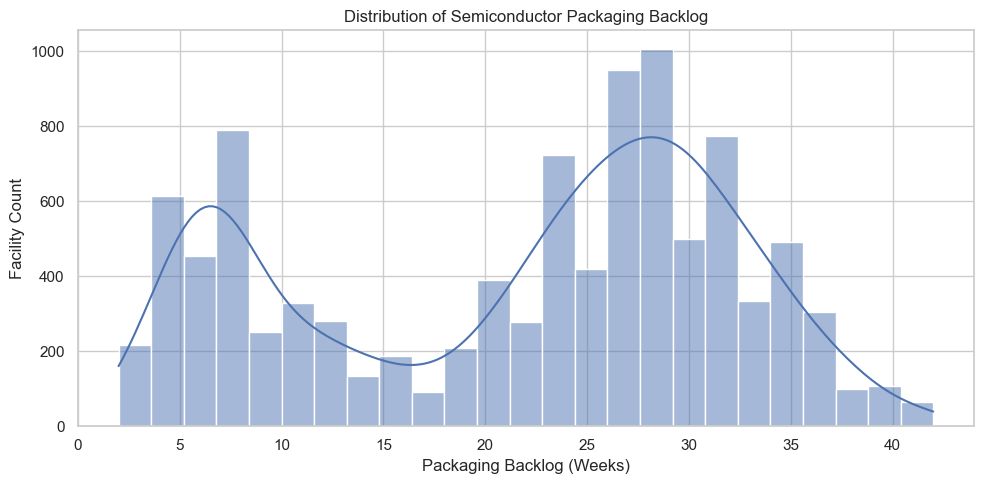

count    10000.000000
mean        21.592900
std         10.568299
min          2.000000
25%         11.000000
50%         25.000000
75%         30.000000
max         42.000000
Name: packaging_backlog_weeks, dtype: float64

In [26]:
# visualize backlog distribution

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_clean,
    x="packaging_backlog_weeks",
    bins=25,
    kde=True
)

plt.title("Distribution of Semiconductor Packaging Backlog")
plt.xlabel("Packaging Backlog (Weeks)")
plt.ylabel("Facility Count")

plt.tight_layout()
plt.show()

display(
    df_clean["packaging_backlog_weeks"].describe()
)

,mean,median,count
advanced_packaging_type,,,
Foveros-3D,28.187798,28.0,1049
CoWoS-S,28.001507,28.0,2655
CoWoS-L,27.967887,28.0,3114
InFO-PoP,11.420849,11.5,1036
Standard_FlipChip,6.100652,6.0,2146


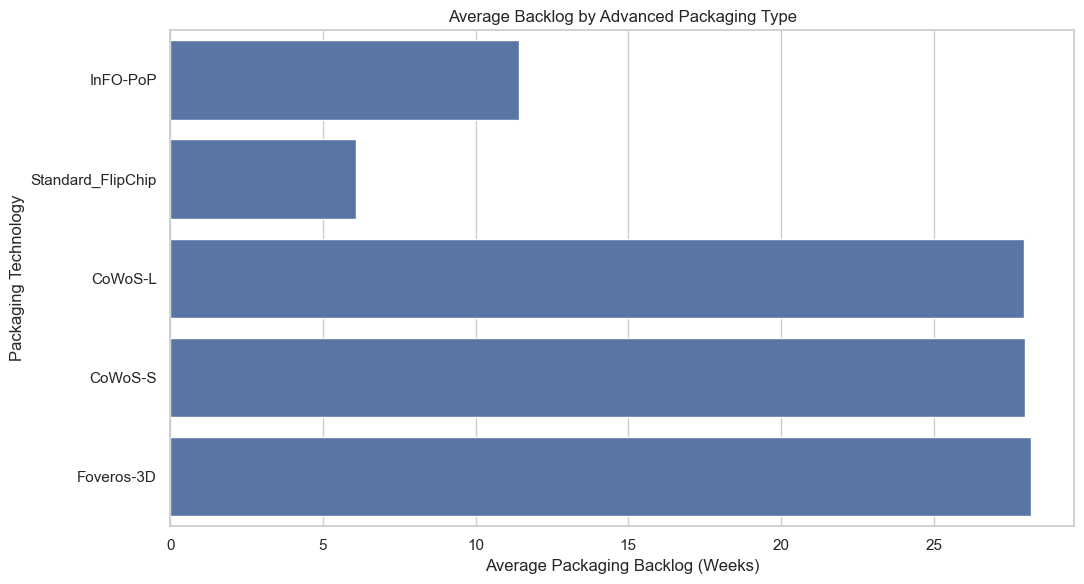

In [30]:
# bar graph of packaging technology vs backlog

packaging_summary = (
    df_clean.groupby("advanced_packaging_type")
    ["packaging_backlog_weeks"]
    .agg(["mean", "median", "count"])
    .sort_values("mean", ascending=False)
)

display(packaging_summary)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=df_clean,
    x="packaging_backlog_weeks",
    y="advanced_packaging_type",
    estimator=np.mean,
    errorbar=None
)

plt.title("Average Backlog by Advanced Packaging Type")
plt.xlabel("Average Packaging Backlog (Weeks)")
plt.ylabel("Packaging Technology")

plt.tight_layout()
plt.show()

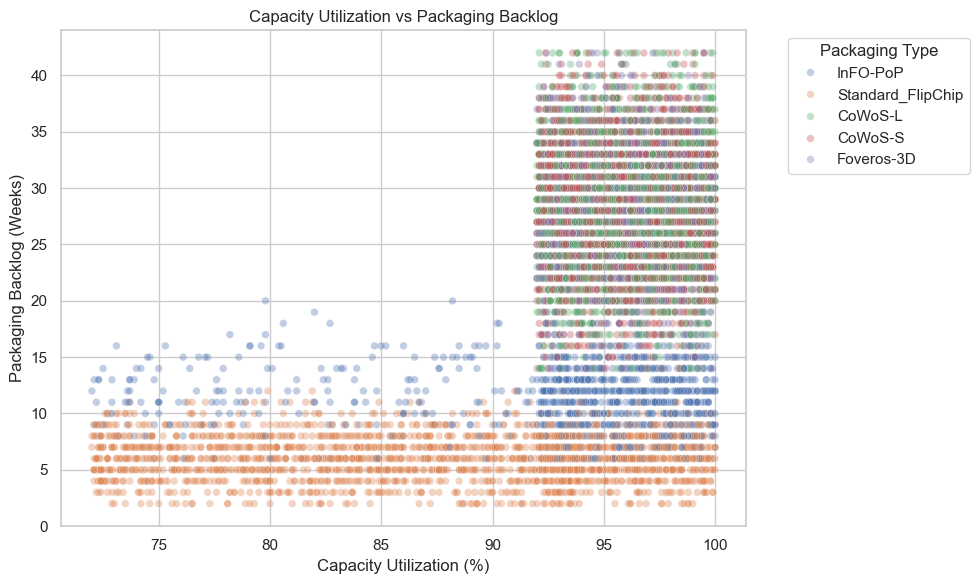

In [32]:
# analyzing relationship between capacity utilization vs backlog


plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean,
    x="capacity_utilization_pct",
    y="packaging_backlog_weeks",
    hue="advanced_packaging_type",
    alpha=0.35,
    s=30
)

plt.title("Capacity Utilization vs Packaging Backlog")
plt.xlabel("Capacity Utilization (%)")
plt.ylabel("Packaging Backlog (Weeks)")
plt.legend(title="Packaging Type", bbox_to_anchor=(1.05, 1))

plt.tight_layout()
plt.show()


,mean,median,count
country_location,,,
Ireland,24.481013,27.0,158
Netherlands,22.444776,25.0,335
Taiwan,22.153108,25.0,2606
USA,22.003574,25.0,2798
Japan,21.330370,25.0,675
South Korea,21.260314,24.0,2739
Germany,20.566667,24.0,450
Singapore,17.326531,14.0,147
China,8.836957,6.5,92


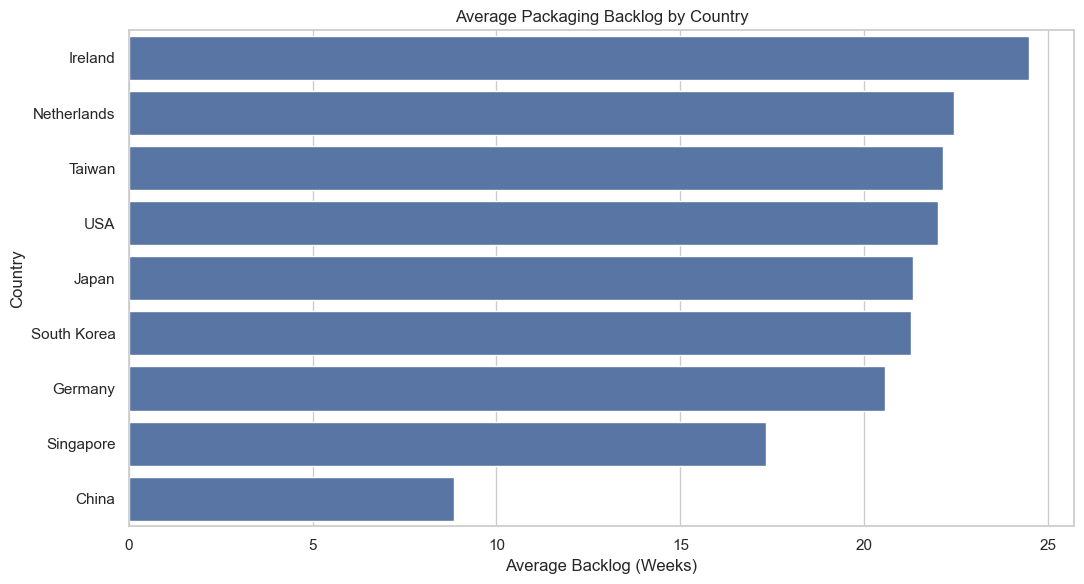

In [34]:
# analyzing backlog by country


country_summary = (
    df_clean.groupby("country_location")
    ["packaging_backlog_weeks"]
    .agg(["mean", "median", "count"])
    .sort_values("mean", ascending=False)
)

display(country_summary)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=country_summary.reset_index(),
    x="mean",
    y="country_location",
    errorbar=None
)

plt.title("Average Packaging Backlog by Country")
plt.xlabel("Average Backlog (Weeks)")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

,mean,count
process_node_nm,,
5nm,24.542762,2093
4nm,24.533143,2097
2nm,24.411487,1271
3nm,24.363599,2456
28nm,13.107477,214
12nm,10.551155,606
7nm,10.334125,1263


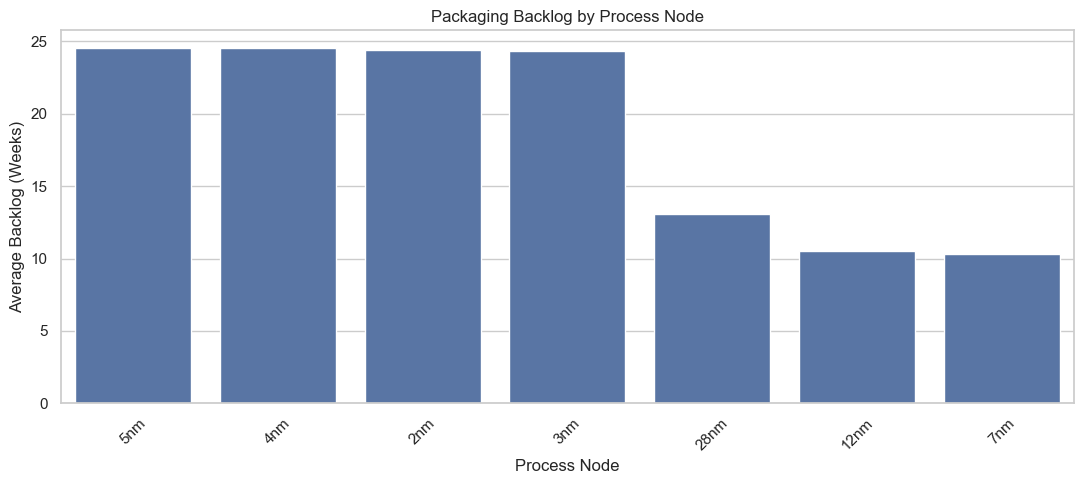

In [36]:
# analyzing backlog by process node

node_summary = (
    df_clean.groupby("process_node_nm")
    ["packaging_backlog_weeks"]
    .agg(["mean", "count"])
    .sort_values("mean", ascending=False)
)

display(node_summary)

plt.figure(figsize=(11, 5))

sns.barplot(
    data=node_summary.reset_index(),
    x="process_node_nm",
    y="mean",
    errorbar=None
)

plt.title("Packaging Backlog by Process Node")
plt.xlabel("Process Node")
plt.ylabel("Average Backlog (Weeks)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Feature Engineering and Data Preparation

The target variable is `packaging_backlog_weeks`.

The analysis uses manufacturing capacity, operational performance, process technology, packaging characteristics, and accelerator requirements to predict backlog duration.

Fields that may directly encode the target or represent downstream risk assessments are excluded to reduce potential data leakage.

Categorical features are one-hot encoded and numeric features are imputed and scaled where necessary.

The dataset is split into 80% training and 20% testing data. Five-fold cross-validation is used on the training portion for model selection.

In [39]:
# select features


target = "packaging_backlog_weeks"

numeric_features = [
    "wafer_size_mm",
    "monthly_capacity_wafers",
    "capacity_utilization_pct",
    "die_yield_pct",
    "defect_density_per_cm2",
    "lithography_lead_time_months",
    "power_consumption_mw",
    "water_recycling_rate_pct",
    "hbm_bandwidth_tb_s"
]

categorical_features = [
    "company_name",
    "country_location",
    "facility_type",
    "process_node_nm",
    "lithography_technology",
    "lithography_tool_supplier",
    "advanced_packaging_type",
    "hbm_integration_spec",
    "target_ai_accelerator_family"
]

feature_columns = numeric_features + categorical_features

X = df_clean[feature_columns].copy()
y = df_clean[target].copy()

print("Number of predictors:", X.shape[1])
print("Features:", feature_columns)
print("Target:", target)


Number of predictors: 18
Features: ['wafer_size_mm', 'monthly_capacity_wafers', 'capacity_utilization_pct', 'die_yield_pct', 'defect_density_per_cm2', 'lithography_lead_time_months', 'power_consumption_mw', 'water_recycling_rate_pct', 'hbm_bandwidth_tb_s', 'company_name', 'country_location', 'facility_type', 'process_node_nm', 'lithography_technology', 'lithography_tool_supplier', 'advanced_packaging_type', 'hbm_integration_spec', 'target_ai_accelerator_family']
Target: packaging_backlog_weeks


In [41]:
# train/test split and preprocessing


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Unknown"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 8000
Testing records: 2000


## Machine Learning Model Development

Four regression models are evaluated:

1. Dummy Regressor — baseline benchmark
2. Bayesian Ridge Regression — regularized linear regression
3. LightGBM Regressor — gradient boosting
4. CatBoost Regressor — gradient boosting

Model selection is based on five-fold cross-validation RMSE on the training dataset.

The selected model is subsequently evaluated on an untouched holdout test set.

In [44]:
# train and compare models


from sklearn.model_selection import cross_validate

models = {
    "Dummy Baseline": DummyRegressor(strategy="median"),
    "Bayesian Ridge": BayesianRidge(),
    "LightGBM": LGBMRegressor(
        n_estimators=200,
        learning_rate=0.05,
        num_leaves=31,
        random_state=42,
        verbosity=-1
    ),
    "CatBoost": CatBoostRegressor(
        iterations=250,
        depth=6,
        learning_rate=0.05,
        random_seed=42,
        verbose=False,
        thread_count=2
    )
}

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

for model_name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "rmse": "neg_root_mean_squared_error",
            "mae": "neg_mean_absolute_error",
            "r2": "r2"
        },
        n_jobs=1
    )

    results.append({
        "Model": model_name,
        "CV_RMSE": -scores["test_rmse"].mean(),
        "CV_MAE": -scores["test_mae"].mean(),
        "CV_R2": scores["test_r2"].mean()
    })

    print(model_name, "completed")

model_results = pd.DataFrame(results).sort_values(
    "CV_RMSE"
).reset_index(drop=True)

display(model_results.round(4))

Dummy Baseline completed
Bayesian Ridge completed


C:\Users\neela\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\neela\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\neela\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\neela\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\neela\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreatePro

LightGBM completed
CatBoost completed


,Model,CV_RMSE,CV_MAE,CV_R2
0,Bayesian Ridge,4.6310,3.5338,0.8079
1,CatBoost,4.6459,3.5464,0.8067
2,LightGBM,4.7258,3.6084,0.7999
3,Dummy Baseline,11.1024,8.8461,-0.1036


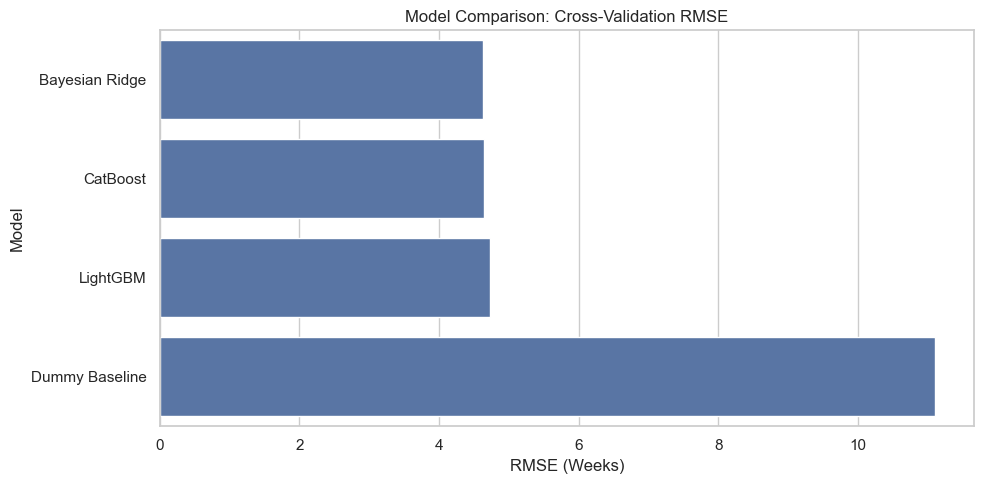

In [46]:
# visualize model comparision

plt.figure(figsize=(10, 5))

sns.barplot(
    data=model_results,
    x="CV_RMSE",
    y="Model",
    errorbar=None
)

plt.title("Model Comparison: Cross-Validation RMSE")
plt.xlabel("RMSE (Weeks)")
plt.ylabel("Model")

plt.tight_layout()
plt.show()

In [48]:
# Select and train the best model

best_model_name = model_results.iloc[0]["Model"]

print("Best model:", best_model_name)

best_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", models[best_model_name])
])

best_pipeline.fit(X_train, y_train)

print("Model training completed successfully.")

Best model: Bayesian Ridge
Model training completed successfully.


## Model Evaluation

In [52]:
# generate test predictions

y_pred = best_pipeline.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Best Model:", best_model_name)
print(f"Test RMSE: {rmse:.3f} weeks")
print(f"Test MAE: {mae:.3f} weeks")
print(f"Test R²: {r2:.3f}")

Best Model: Bayesian Ridge
Test RMSE: 4.642 weeks
Test MAE: 3.506 weeks
Test R²: 0.806


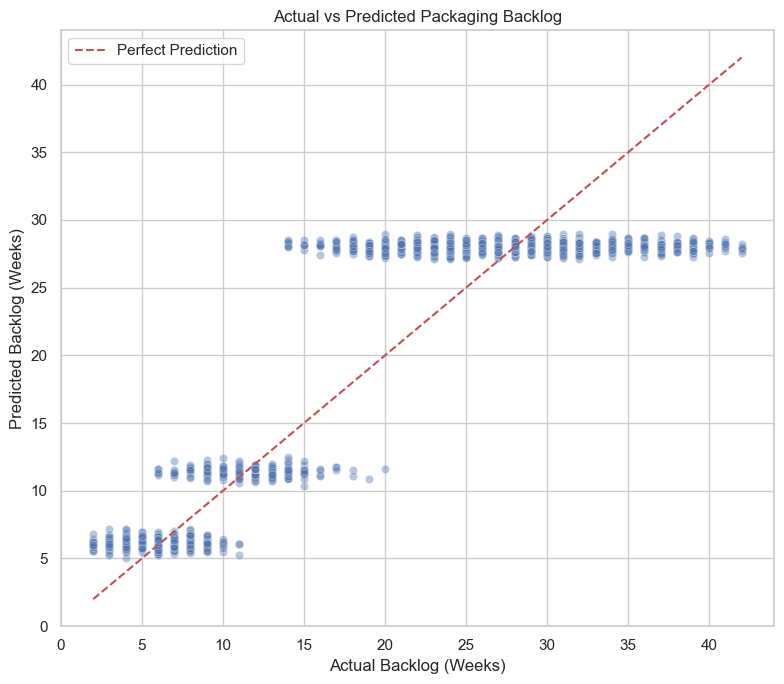

In [54]:
# Actual vs. predicted backlog

plt.figure(figsize=(8, 7))

sns.scatterplot(
    x=y_test,
    y=y_pred,
    alpha=0.4
)

limits = [
    min(y_test.min(), y_pred.min()),
    max(y_test.max(), y_pred.max())
]

plt.plot(limits, limits, "r--", label="Perfect Prediction")

plt.title("Actual vs Predicted Packaging Backlog")
plt.xlabel("Actual Backlog (Weeks)")
plt.ylabel("Predicted Backlog (Weeks)")
plt.legend()

plt.tight_layout()
plt.show()

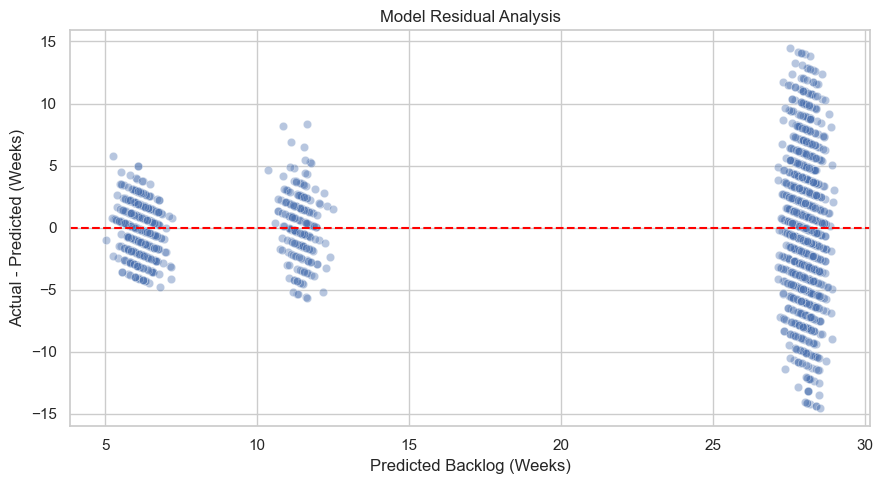

In [56]:
# residual analysis


residuals = y_test.to_numpy() - y_pred

plt.figure(figsize=(9, 5))

sns.scatterplot(
    x=y_pred,
    y=residuals,
    alpha=0.4
)

plt.axhline(0, color="red", linestyle="--")

plt.title("Model Residual Analysis")
plt.xlabel("Predicted Backlog (Weeks)")
plt.ylabel("Actual - Predicted (Weeks)")

plt.tight_layout()
plt.show()


,Feature,Importance
15,advanced_packaging_type,9.724631
12,process_node_nm,0.020842
4,defect_density_per_cm2,0.019272
1,monthly_capacity_wafers,0.013227
9,company_name,0.004628
17,target_ai_accelerator_family,0.004463
10,country_location,0.004030
13,lithography_technology,0.003361
8,hbm_bandwidth_tb_s,0.001337
11,facility_type,0.001105


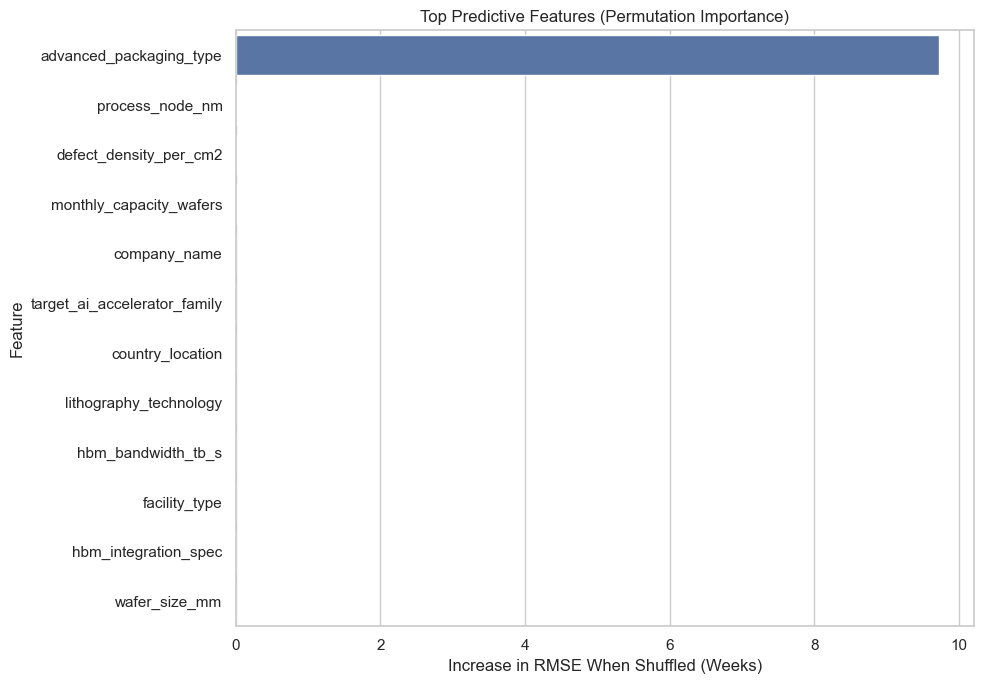

In [58]:
# Feature importance
# We can use permutation importance, which measures how much predictive performance deteriorates when a feature is shuffled.


from sklearn.inspection import permutation_importance

importance = permutation_importance(
    best_pipeline,
    X_test,
    y_test,
    n_repeats=3,
    random_state=42,
    scoring="neg_root_mean_squared_error",
    n_jobs=1
)

importance_df = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": importance.importances_mean
}).sort_values("Importance", ascending=False)

display(importance_df)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df.head(12),
    x="Importance",
    y="Feature",
    errorbar=None
)

plt.title("Top Predictive Features (Permutation Importance)")
plt.xlabel("Increase in RMSE When Shuffled (Weeks)")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

## Operational Prioritization

To translate model predictions into actionable operational intelligence, an illustrative Backlog Attention Score is constructed.

The score combines:

- Predicted packaging backlog: 70% weight
- Capacity utilization: 30% weight

Higher scores indicate facilities with longer predicted queues and greater capacity utilization.

The score is a transparent business prioritization heuristic, not a formally optimized resource allocation policy. It is intended to support exploratory decision-making.

Facilities are categorized into Monitor, Elevated, and Urgent attention tiers.

In [61]:
# Generate out-of-fold predictions for all facilities

# We want a prediction for every facility that we can export to Tableau.
# Using out-of-fold predictions avoids showing predictions generated by a model trained directly on the same facility record.


from sklearn.model_selection import cross_val_predict
from sklearn.base import clone

# Generate out-of-fold predictions
all_predictions = cross_val_predict(
    clone(best_pipeline),
    X,
    y,
    cv=cv,
    n_jobs=1
)

dashboard_df = df_clean.copy()

dashboard_df["predicted_backlog_weeks"] = (
    np.maximum(all_predictions, 0)
)

dashboard_df["prediction_error_weeks"] = (
    dashboard_df["packaging_backlog_weeks"]
    - dashboard_df["predicted_backlog_weeks"]
)

dashboard_df["absolute_prediction_error_weeks"] = (
    dashboard_df["prediction_error_weeks"].abs()
)

print("Facilities with predictions:", len(dashboard_df))

display(dashboard_df[[
    "facility_id",
    "packaging_backlog_weeks",
    "predicted_backlog_weeks"
]].head())

Facilities with predictions: 10000


,facility_id,packaging_backlog_weeks,predicted_backlog_weeks
0,FAB-SMIC-00CCF968,19,10.836802
1,FAB-SMIC-02D12E75,5,5.761721
2,FAB-SMIC-03578D8E,5,5.473130
3,FAB-SMIC-03BC7BA8,6,5.286469
4,FAB-SMIC-04E97DBE,19,27.464688


In [67]:
# calculate the operational attention score

# Convert predicted backlog to a 0–100 score
backlog_scale = 42.0

dashboard_df["backlog_component"] = (
    dashboard_df["predicted_backlog_weeks"]
    / backlog_scale * 100
).clip(0, 100)

# Capacity utilization is already expressed as a percentage
dashboard_df["utilization_component"] = (
    dashboard_df["capacity_utilization_pct"]
).clip(0, 100)

# Weighted attention score
dashboard_df["backlog_attention_score"] = (
    0.70 * dashboard_df["backlog_component"]
    + 0.30 * dashboard_df["utilization_component"]
).round(2)

# Assign attention tiers
dashboard_df["attention_tier"] = pd.cut(
    dashboard_df["backlog_attention_score"],
    bins=[-np.inf, 50, 70, np.inf],
    labels=["Monitor", "Elevated", "Urgent"]
)

# Flag predicted long queues
dashboard_df["predicted_28plus_week_backlog"] = (
    dashboard_df["predicted_backlog_weeks"] >= 28
).astype(int)

display(
    dashboard_df["attention_tier"].value_counts()
)

attention_tier
Urgent      6818
Monitor     3178
Elevated       4
Name: count, dtype: int64

In [69]:
# Identify top priority facilities

priority_facilities = (
    dashboard_df.sort_values(
        "backlog_attention_score",
        ascending=False
    )
    .head(20)
)

display(priority_facilities[[
    "facility_id",
    "company_name",
    "country_location",
    "advanced_packaging_type",
    "capacity_utilization_pct",
    "predicted_backlog_weeks",
    "backlog_attention_score",
    "attention_tier"
]])

,facility_id,company_name,country_location,advanced_packaging_type,capacity_utilization_pct,predicted_backlog_weeks,backlog_attention_score,attention_tier
420,FAB-TSMC-186AF870,TSMC,Germany,CoWoS-L,97.9,29.940717,79.27,Urgent
4774,FAB-TSMC-07FA3937,TSMC,Taiwan,CoWoS-L,98.6,29.427058,78.63,Urgent
555,FAB-INTC-0C2DCFFE,Intel Foundry,Ireland,Foveros-3D,100.0,29.110498,78.52,Urgent
547,FAB-INTC-02A16F27,Intel Foundry,Ireland,Foveros-3D,96.9,29.491287,78.22,Urgent
604,FAB-INTC-56ABA034,Intel Foundry,Ireland,Foveros-3D,99.1,29.067451,78.18,Urgent
6729,FAB-TSMC-D126CA4E,TSMC,Taiwan,CoWoS-L,99.4,29.012853,78.17,Urgent
641,FAB-INTC-8477CF9F,Intel Foundry,Ireland,Foveros-3D,98.9,29.092523,78.16,Urgent
678,FAB-INTC-D8D39F1E,Intel Foundry,Ireland,Foveros-3D,99.2,29.036280,78.15,Urgent
549,FAB-INTC-0342F503,Intel Foundry,Ireland,Foveros-3D,99.1,29.040895,78.13,Urgent
2034,FAB-SKHY-2840DFC0,SK Hynix,South Korea,CoWoS-L,98.7,29.108563,78.12,Urgent


## Export Files for Tableau

In [72]:
# create path for tableau exports

from pathlib import Path

output_dir = Path("tableau_exports")
output_dir.mkdir(exist_ok=True)

print("Export folder ready:", output_dir.resolve())

Export folder ready: C:\Users\neela\Downloads\ai_semiconductor_supply_chain_predictive_bottlenecks_and_capacity_optimization\tableau_exports


In [74]:
# export prediction and summary datasets


# 1. Facility-level predictions and attention scores
dashboard_df.to_csv(
    output_dir / "dashboard2_facility_predictions.csv",
    index=False
)

# 2. Model comparison
model_results.to_csv(
    output_dir / "model_comparison.csv",
    index=False
)

# 3. Feature importance
importance_df.to_csv(
    output_dir / "feature_importance.csv",
    index=False
)

# 4. Packaging summary
packaging_export = (
    dashboard_df.groupby("advanced_packaging_type")
    .agg(
        facility_count=("facility_id", "nunique"),
        avg_actual_backlog=("packaging_backlog_weeks", "mean"),
        avg_predicted_backlog=("predicted_backlog_weeks", "mean"),
        avg_utilization=("capacity_utilization_pct", "mean")
    )
    .reset_index()
)

packaging_export.to_csv(
    output_dir / "packaging_summary.csv",
    index=False
)

# 5. Holdout model metrics
model_metrics = pd.DataFrame([{
    "Model": best_model_name,
    "Holdout_RMSE": rmse,
    "Holdout_MAE": mae,
    "Holdout_R2": r2
}])

model_metrics.to_csv(
    output_dir / "model_holdout_metrics.csv",
    index=False
)

# 6. Save trained model
joblib.dump(
    best_pipeline,
    output_dir / "packaging_backlog_model.joblib"
)

print("All exports completed successfully!")

for file in output_dir.iterdir():
    print(file.name)


All exports completed successfully!
dashboard2_facility_predictions.csv
feature_importance.csv
model_comparison.csv
model_holdout_metrics.csv
packaging_backlog_model.joblib
packaging_summary.csv


In [76]:
# final checks to see if tableau exports and results are correct


assert len(dashboard_df) == len(df_clean)

assert dashboard_df["facility_id"].is_unique

assert dashboard_df[
    "predicted_backlog_weeks"
].notna().all()

assert dashboard_df[
    "backlog_attention_score"
].between(0, 100).all()

print("All validation checks passed.")

print("\nModel:", best_model_name)
print("Holdout RMSE:", round(rmse, 3))
print("Holdout MAE:", round(mae, 3))
print("Holdout R2:", round(r2, 3))

print("\nTop 5 facilities requiring attention:")

display(priority_facilities[[
    "facility_id",
    "predicted_backlog_weeks",
    "backlog_attention_score"
]].head())


All validation checks passed.

Model: Bayesian Ridge
Holdout RMSE: 4.642
Holdout MAE: 3.506
Holdout R2: 0.806

Top 5 facilities requiring attention:


,facility_id,predicted_backlog_weeks,backlog_attention_score
420,FAB-TSMC-186AF870,29.940717,79.27
4774,FAB-TSMC-07FA3937,29.427058,78.63
555,FAB-INTC-0C2DCFFE,29.110498,78.52
547,FAB-INTC-02A16F27,29.491287,78.22
604,FAB-INTC-56ABA034,29.067451,78.18
